In [2]:
import gc
import pickle
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import interpolate_motion
from spikeinterface.curation import compute_merge_unit_groups
from spikeinterface.exporters import export_to_phy
from spikeinterface.widgets import plot_motion_info
from tqdm import tqdm

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

# Setup
GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
STIM_STREAM = NPRW_CFG.get("stim_data_stream")
RADII = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))
RATES = PARAMS.NPRW_rate_est
ARTRMV_MS_BEFORE = float(RATES.get("remove_ms_before", 20.0))
ARTRMV_TAIL_MS = float(RATES.get("remove_tail_ms_after", 20.0))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk)
si.set_global_job_kwargs(**global_job_kwargs)
job_kwargs = dict(n_jobs=-1, progress_bar=True, chunk_duration="1s")

DRIFT_CKPT = OUT_BASE / "checkpoints" / "NPRW_drift"
SORT_CKPT = OUT_BASE / "checkpoints" / "sorting_results" / "NPRW_concat_blanking"
DRIFT_CKPT.mkdir(parents=True, exist_ok=True)
SORT_CKPT.mkdir(parents=True, exist_ok=True)

n_channels = 128
fs = 30000.0

# Load probe geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)


def blank_session(rec, stim_arrays, fs, ms_before, tail_ms):
    """Zero out stim artifact windows using this session's own local trigger indices."""
    block_bounds = stim_arrays.get("block_bounds_samples")
    starts = block_bounds[:, 0]
    ends = block_bounds[:, 1]
    n_total = rec.get_num_samples()

    valid = (ends > starts) & (starts >= 0) & (starts < n_total)
    starts = starts[valid]
    ends = ends[valid]
    if not starts.size:
        return rec

    dur_ms = (ends - starts) * 1000.0 / fs
    ms_after = float(dur_ms.max() + tail_ms)
    return si.preprocessing.remove_artifacts(
        rec, list_triggers=starts.tolist(), ms_before=ms_before, ms_after=ms_after, mode="zeros",
    )
    

In [ ]:
# Preprocess and  -> blank stim artifacts
sess_folders = rcp.list_intan_sessions(INTAN_ROOT)

print(f"Found {len(sess_folders)} Intan sessions")
SKIP_SESSIONS = {5}  # 0-indexed, 6th session

BLANKED_DIR = SORT_CKPT / "blanked_sessions"
BLANKED_DIR.mkdir(parents=True, exist_ok=True)

for i, sess in enumerate(tqdm(sess_folders, desc="Processing sessions")):
    if i in SKIP_SESSIONS:
        tqdm.write(f"[{sess.name}] skipping (index {i}, manually excluded)")
        continue
    sess_save_path = BLANKED_DIR / sess.name
    if sess_save_path.exists():
        tqdm.write(f"[{sess.name}] already saved, skipping")
        continue

    tqdm.write(f"[{sess.name}] loading, filtering, blanking")
    rec_raw = se.read_split_intan_files(sess, mode="concatenate", stream_name=INTAN_STREAM, use_names_as_ids=True)
    rec_raw = spre.unsigned_to_signed(rec_raw)
    rec_raw = rec_raw.set_probe(nprw_probe)
    rec_raw = rcp.reorder_recording_to_geometry(rec_raw, intan_probe_mapping)

    rec_bp = spre.bandpass_filter(rec_raw, freq_min=float(PARAMS.highpass_hz), freq_max=float(PARAMS.lowpass_hz))
    rec_bp = spre.astype(rec_bp, dtype="float32")
    rec_cmr = spre.common_reference(rec_bp, reference="local", operator="median", local_radius=RADII)

    stim_npz_path = NPRW_AUX_DATA / f"{sess.name}_Intan_streams" / "stim_stream.npz"
    if stim_npz_path.exists():
        loaded = np.load(stim_npz_path, allow_pickle=True)
        stim_arrays = {k: loaded[k] for k in loaded.files if k != "meta"}
    else:
        stim_arrays = rcp.extract_stim_npz(
            sess=sess, out_dir=NPRW_AUX_DATA,
            stim_stream_name=STIM_STREAM,
            chanmap_perm=intan_probe_mapping,
        )

    rec_blanked = blank_session(rec_cmr, stim_arrays, fs, ARTRMV_MS_BEFORE, ARTRMV_TAIL_MS)

    # Save to disk per session
    rec_blanked_saved = rec_blanked.save(folder=sess_save_path, overwrite=True, **job_kwargs)
    tqdm.write(f"  saved {sess.name}: {rec_blanked_saved.get_total_duration():.1f}s, "
               f"{stim_arrays['block_bounds_samples'].shape[0]} stim blocks blanked")

    del rec_raw, rec_bp, rec_cmr, rec_blanked, rec_blanked_saved, loaded, stim_arrays
    gc.collect()


Found 17 Intan sessions


Processing sessions:   0%|                                                                                                                                                                                                                                                            | 0/17 [00:00<?, ?it/s]

[BL_closed_loop_STIM_003_250528_140952] already saved, skipping
[BL_closed_loop_STIM_003_250528_143512] already saved, skipping
[BL_closed_loop_STIM_003_250528_143802] already saved, skipping
[BL_closed_loop_STIM_003_250528_144603] already saved, skipping
[BL_closed_loop_STIM_003_250528_145904] already saved, skipping
[BL_closed_loop_STIM_003_250528_150615] already saved, skipping
[BL_closed_loop_STIM_003_250528_150847] loading, filtering, blanking


: 

: 

: 

In [ ]:
# Sorting up to file 5 now, because file 6/7 gives an error?

In [ ]:
# Reload the recordings and concatenate
per_session_recs = []
end_idx = 5
for sess in tqdm(sess_folders[:5], desc="Reloading blanked sessions"):
    sess_save_path = BLANKED_DIR / sess.name
    per_session_recs.append(si.load(sess_save_path))

rec_concat = si.concatenate_recordings(per_session_recs)
print(f"Concatenated: {rec_concat.get_total_duration():.1f}s, {rec_concat.get_num_channels()} channels")

session_boundaries = np.concatenate([[0], np.cumsum([r.get_num_samples() for r in per_session_recs])])
sess_names = [s.name for s in sess_folders]

with open(SORT_CKPT / "session_index.pkl", "wb") as f:
    pickle.dump({"session_boundaries": session_boundaries, "sess_names": sess_names}, f)

Reloading blanked sessions: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00,  7.08it/s]


Concatenated: 1262.3s, 128 channels


290.2272

In [9]:
session_boundaries = np.concatenate([[0], np.cumsum([r.get_num_samples() for r in per_session_recs])])
sess_names = [s.name for s in sess_folders]

with open(SORT_CKPT / "session_index.pkl", "wb") as f:
    pickle.dump({"session_boundaries": session_boundaries, "sess_names": sess_names}, f)

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/3 [00:00<?, ?it/s]

Solve:   0%|          | 0/2 [00:00<?, ?it/s]

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=30,000 - chunk_memory=7.32 MiB - total_memory=87.89 MiB - chunk_duration=1.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 37,869,568 samples 
                       1,262.32s (21.04 minutes) - int16 dtype - 9.03 GiB


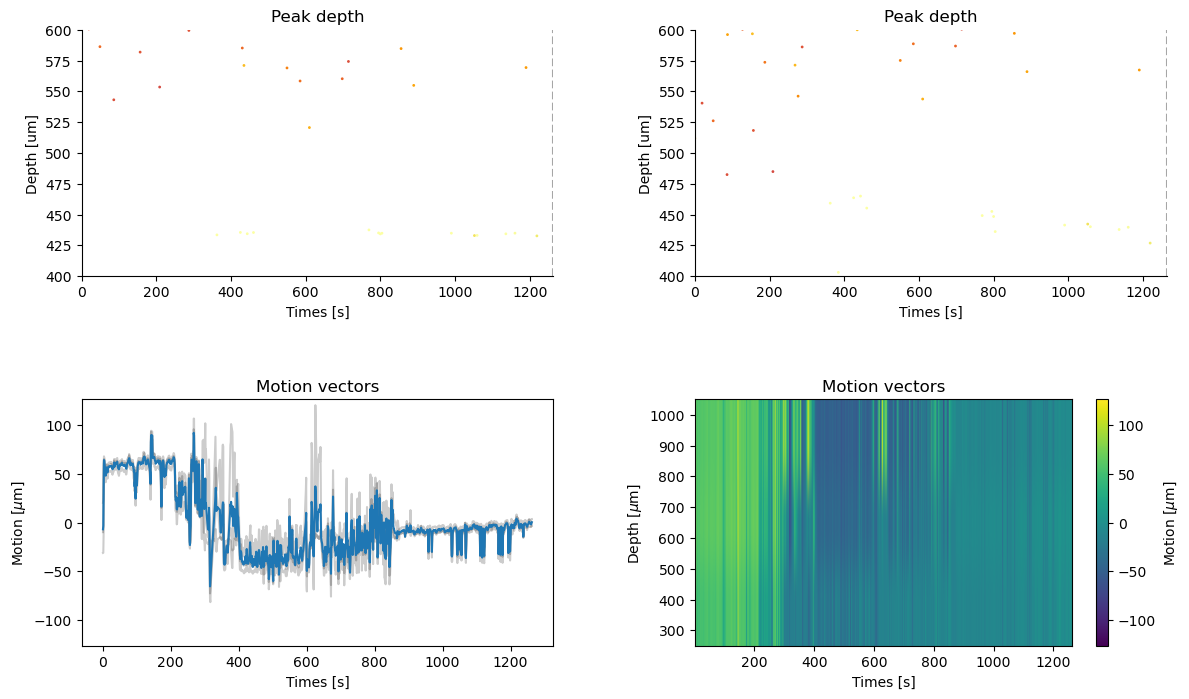

In [10]:
# Motion estimation on the full concatenated (blanked) recording
motion, motion_info = spre.compute_motion(
    rec_concat, preset="dredge", folder=DRIFT_CKPT, output_motion_info=True, overwrite=True, **job_kwargs
)
with open(SORT_CKPT / "motion_info.pkl", "wb") as f:
    pickle.dump(motion_info, f)

%matplotlib inline
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec_concat,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

interpolated_recording = interpolate_motion(
    recording=rec_concat, motion=motion_info['motion'],
    border_mode="force_extrapolate"
)

# Save the corrected recording to disk so it's serializable for the sorter
saved_rec_path = SORT_CKPT / "rec_corrected_saved"
interpolated_recording_i16 = spre.astype(interpolated_recording, dtype="int16")
rec_corrected_saved = interpolated_recording_i16.save(folder=saved_rec_path, overwrite=True, **job_kwargs)
print(rec_corrected_saved)

In [12]:
saved_rec_path = SORT_CKPT / "rec_corrected_saved"
interpolated_recording = si.load(saved_rec_path)

with open(SORT_CKPT / "session_index.pkl", "rb") as f:
    session_index = pickle.load(f)
session_boundaries = session_index["session_boundaries"]
sess_names = session_index["sess_names"]

In [13]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=interpolated_recording,
    folder=SORT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, interpolated_recording)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=SORT_CKPT / "sorting_curated", overwrite=True)

# Reload
sorting = si.load(SORT_CKPT / "sorting_curated")

folder = SORT_CKPT / "analyzer_pre_slay"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    subprocess.run(["rm", "-rf", str(folder)], check=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:38<00:00, 38.57s/it]
/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


In [14]:
# Phy export: post-curation, pre-SLAY
analyzer_precuration = si.create_sorting_analyzer(
    sorting, interpolated_recording,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_pre_slay",
    overwrite=True,
    **job_kwargs,
)
analyzer_precuration.compute(
    ["random_spikes", "waveforms", "templates", "noise_levels", "spike_amplitudes", "unit_locations"],
    **job_kwargs,
)
export_to_phy(
    analyzer_precuration,
    output_folder=SORT_CKPT / "phy_pre_slay",
    **job_kwargs,
)
print(f"Phy export (pre-SLAY) -> {SORT_CKPT / 'phy_pre_slay'}")

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

compute_waveforms (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

write_binary_recording (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/postprocessing/template_similarity.py:345: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  overlapping_ids = overlapping_j_list[i]


Fitting PCA:   0%|          | 0/221 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/221 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/NPRW_concat_blanking/phy_pre_slay/params.py
Phy export (pre-SLAY) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/NPRW_concat_blanking/phy_pre_slay


In [16]:
# SLAY on the full concatenated sorting
analyzer_concat_path = SORT_CKPT / "my_sorting_analyzer_concat"
analyzer_concat = si.create_sorting_analyzer(
    sorting, interpolated_recording,
    format="binary_folder", folder=analyzer_concat_path,
    overwrite=True, **job_kwargs,
)
analyzer_concat.compute(
    ["random_spikes", "templates", "template_similarity", "correlograms"],
    **job_kwargs,
)

merge_groups = compute_merge_unit_groups(analyzer_concat, preset="slay", resolve_graph=True)


estimate_sparsity (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

In [30]:
analyzer_concat

SortingAnalyzer: 128 channels - 221 units - 1 segments - binary_folder - sparse - has recording
Loaded 4 extensions: random_spikes, templates, template_similarity, correlograms

In [35]:
merge_groups

[[np.int64(41), np.int64(198)],
 [np.int64(166), np.int64(204)],
 [np.int64(185), np.int64(192)]]

In [ ]:
if merge_groups is not None and len(merge_groups) > 0:
    analyzer_concat = analyzer_concat.merge_units(merge_unit_groups=merge_groups)
    print(f"[concat] {analyzer_concat.sorting.get_num_units()} units after SLAY merge")
else:
    print(f"[concat] no merges found, {analyzer_concat.sorting.get_num_units()} units")

sorting_merged = analyzer_concat.sorting

# Per-session filter: FR + SNR + RP, keep units passing in ANY session
good_units_any_session = set()

In [ ]:
for i, sess_name in enumerate(tqdm(sess_names[:end_idx], desc="Per-session threshold")):
    t_start = int(session_boundaries[i])
    t_end = int(session_boundaries[i + 1])
    dur_s = (t_end - t_start) / sorting_merged.get_sampling_frequency()
    if dur_s < 10:
        tqdm.write(f"[{sess_name}] skipping ({dur_s:.1f}s too short)")
        continue

    rec_sess = interpolated_recording.frame_slice(start_frame=t_start, end_frame=t_end)
    sorting_sess = sorting_merged.frame_slice(start_frame=t_start, end_frame=t_end)

    analyzer_sess = si.create_sorting_analyzer(sorting_sess, rec_sess, format="memory")
    analyzer_sess.compute(
        ["random_spikes", "templates", "noise_levels", "quality_metrics"],
        extension_params={
            "quality_metrics": {
                "metric_names": ["firing_rate", "snr", "rp_violation"],
                "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},
            },
        },
        **job_kwargs,
    )
    qm_sess = analyzer_sess.get_extension("quality_metrics").get_data()
    passing = qm_sess[
        (qm_sess["firing_rate"] > 0.1) &
        (qm_sess["snr"] > 3.0) &
        (qm_sess["rp_contamination"] < 0.2)
    ].index
    good_units_any_session.update(passing.tolist())
    tqdm.write(f"[{sess_name}] {len(passing)}/{len(qm_sess)} units pass ({dur_s:.1f}s)")

print(f"\nTotal good units across all sessions: {len(good_units_any_session)}")
sorting_merged_filtered = sorting_merged.select_units(list(good_units_any_session))

Per-session threshold:   0%|                                                                                                                                                                                                                                                           | 0/5 [00:00<?, ?it/s]

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/73 [00:00<?, ?it/s]

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/metrics/quality/misc_metrics.py:188: UserWarning: Operator 'median' requires 'waveforms' extension. Falling back to 'average'. To use 'median', please compute the 'waveforms' extension first with: analyzer.compute('waveforms')
  warnings.warn(
Per-session threshold:  20%|████████████████████████████████████████████████▌                                                                                                                                                                                                  | 1/5 [00:04<00:16,  4.10s/it]

[BL_closed_loop_STIM_003_250528_140952] 59/221 units pass (290.2s)


... (16 outputs left out)

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/metrics/quality/misc_metrics.py:188: UserWarning: Operator 'median' requires 'waveforms' extension. Falling back to 'average'. To use 'median', please compute the 'waveforms' extension first with: analyzer.compute('waveforms')
  warnings.warn(
Per-session threshold: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:18<00:00,  3.64s/it]

[BL_closed_loop_STIM_003_250528_145904] 64/221 units pass (387.9s)

Total good units across all sessions: 140


In [ ]:
# Phy export: post-SLAY + filtered
analyzer_final = si.create_sorting_analyzer(
    sorting_merged_filtered, interpolated_recording,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_final",
    overwrite=True,
    **job_kwargs,
)

analyzer_final.compute(
    [
        "random_spikes", "waveforms", "templates", "noise_levels",
        "spike_amplitudes", "unit_locations", "isi_histograms",
        "correlograms", "principal_components", "quality_metrics",
        "template_similarity",
    ],
    extension_params={
        "principal_components": {"n_components": 3, "mode": "by_channel_global", "whiten": True},
        "quality_metrics": {"metric_names": ["snr", "firing_rate", "rp_violation"],
            "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},},
    },
    **job_kwargs,
)


export_to_phy(
    analyzer_final,
    output_folder=SORT_CKPT / "phy_final",
    remove_if_exists=True,
    **job_kwargs,
)
print(f"Phy export (final) -> {SORT_CKPT / 'phy_final'}")


estimate_sparsity (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

compute_waveforms (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/140 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/140 [00:00<?, ?it/s]

Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

write_binary_recording (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/1263 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/NPRW_concat_blanking/phy_final/params.py
Phy export (final) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/NPRW_concat_blanking/phy_final


In [41]:
#merge_units censor_ms to 5 samples, to remove duplicate spikes
remove_unit_ids = [198, 41, 11, 28, 46, 106, 47, 62, 67, 73, 78, 82, 86, 124, 134, 137, 139, 156, 168, 169, 197]

# remove some units
analyzer_clean = analyzer_final.remove_units(remove_unit_ids=remove_unit_ids, )
analyzer_clean = analyzer_clean.save_as(folder=SORT_CKPT / "analyzer_blanking_cleaned", format="binary_folder")

In [42]:
analyzer_clean

SortingAnalyzer: 128 channels - 119 units - 1 segments - binary_folder - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, isi_histograms, correlograms, principal_components, quality_metrics, template_similarity, spike_amplitudes

In [46]:
# Split per session and save spike trains
for i, sess_name in enumerate(tqdm(sess_names[:end_idx], desc="Saving spike trains")):
    t_start = int(session_boundaries[i])
    t_end = int(session_boundaries[i + 1])

    spike_trains = {}
    for uid in sorting_merged_filtered.unit_ids:
        st = sorting_merged_filtered.get_unit_spike_train(uid, segment_index=0)
        mask = (st >= t_start) & (st < t_end)
        spike_trains[str(uid)] = st[mask] - t_start

    total = sum(len(v) for v in spike_trains.values())
    tqdm.write(f"[{sess_name}] total_spikes={total}")

    out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
    out_path.mkdir(parents=True, exist_ok=True)

    fs = float(sorting_merged_filtered.get_sampling_frequency())
    savemat(out_path / "spike_trains.mat",
            {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": fs})
    np.savez(out_path / "spike_trains.npz",
             **{f"unit_{k}": v for k, v in spike_trains.items()}, fs=fs)

Saving spike trains:   0%|                                                                                                                                                                                                                                                             | 0/5 [00:00<?, ?it/s]

[BL_closed_loop_STIM_003_250528_140952] total_spikes=512057


Saving spike trains:  40%|██████████████████████████████████████████████████████████████████████████████████████████████████                                                                                                                                                   | 2/5 [00:00<00:00,  4.84it/s]

[BL_closed_loop_STIM_003_250528_143512] total_spikes=123543
[BL_closed_loop_STIM_003_250528_143802] total_spikes=292880


Saving spike trains:  80%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████                                                 | 4/5 [00:00<00:00,  5.70it/s]

[BL_closed_loop_STIM_003_250528_144603] total_spikes=262963
[BL_closed_loop_STIM_003_250528_145904] total_spikes=325497


Saving spike trains: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.52it/s]
